# Projeto 2: Reinforcement Learning em ambientes não determinísticos

**Ambiente:** `Taxi-v4` (Gymnasium) | **Algoritmos:** Q-learning e Sarsa

Este relatório apresenta o treinamento de agentes Q-learning e Sarsa no Taxi-v4 em duas versões:

* **determinístico**: cada ação tem sempre o efeito pretendido;
* **chuvoso** (`is_rainy=True, rainy_probability=0.6`): um movimento sai como pretendido com probabilidade 0,6 e desvia para cada lateral com probabilidade 0,2.

Organização do código (ver `README.md`):

| Arquivo | Conteúdo |
|---|---|
| `agentes.py` | classes `QLearning` e `Sarsa` |
| `comum.py` | hiperparâmetros, treino, teste, meta de reward e gráficos |
| `exp_deterministico.py` | atividades 1, 2 e 3 |
| `exp_chuvoso.py` | atividades 4 e 5 |
| `relatorio.ipynb` | este relatório |

O notebook usa os resultados salvos em `results/` e `data/`. Se eles não existirem, os scripts são executados automaticamente (cerca de 1 minuto).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import comum
from comum import (HIPERPARAMETROS, N_TREINOS, N_TESTES, MAX_PASSOS_TREINO, MAX_PASSOS_TESTE, ALGORITMOS,
                   retorno_otimo, carregar_resultados, plot_execucoes, plot_comparacao, figura_com_zoom,
                   episodio_convergencia, media_movel)
%matplotlib inline

if not (os.path.exists('results/deterministico.npz') and os.path.exists('results/chuvoso.npz')):
    import exp_deterministico, exp_chuvoso
    exp_deterministico.main()
    exp_chuvoso.main()

treino, testes = carregar_resultados('deterministico', 'chuvoso')
metas = {amb: retorno_otimo(amb) for amb in comum.AMBIENTES}
pd.set_option('display.precision', 2)

## Hiperparâmetros e metodologia

Os mesmos hiperparâmetros são usados para **os dois algoritmos e os dois ambientes**, como pede o enunciado.
Eles foram escolhidos após uma busca curta (α ∈ {0,1; 0,3; 0,5; 0,7}, decaimento de ε ∈ {0,99; 0,995; 0,998; 0,999}) buscando aprendizado rápido e estável nos dois ambientes:

* **α = 0,3**: valores maiores (0,5 a 0,7) aprendiam mais rápido no determinístico, mas ficavam instáveis no chuvoso (o ruído das transições faz a q-table oscilar); 0,1 era lento demais.
* **γ = 0,99**: a recompensa de +20 só chega no fim do episódio, então o agente precisa valorizar o futuro.
* **ε de 1,0 até 0,01, multiplicado por 0,998 a cada episódio**: exploração total no início e política quase gulosa a partir do episódio ~2300.
* **5000 episódios** por treino, com o limite padrão de 200 passos por episódio.

Treino: 5 execuções independentes (sementes 0 a 4) por algoritmo e ambiente.
Teste: política gulosa (`argmax` da q-table), 100 episódios com as mesmas sementes (10000 a 10099) para todos os agentes, limite de 1000 passos. Um episódio que atinge o limite conta como **falha**.

**Meta de reward.** Como o Taxi tem o modelo de transições disponível (`env.P`), calculamos por *value iteration* a política ótima e o reward esperado por episódio que ela obtém, partindo da distribuição de estados iniciais. Essa é a linha tracejada nos gráficos.

In [2]:
print('Hiperparâmetros:', HIPERPARAMETROS)
pd.DataFrame({'meta de reward (política ótima)': metas})

Hiperparâmetros: {'alpha': 0.3, 'gamma': 0.99, 'epsilon': 1.0, 'epsilon_min': 0.01, 'epsilon_dec': 0.998, 'episodes': 5000}


,meta de reward (política ótima)
deterministico,7.93
chuvoso,-3.96


---
# Parte A: ambiente determinístico

## Atividade 1: treinamento do Q-learning (5 execuções)

Cada curva é uma execução de treino (média móvel de 50 episódios do reward acumulado). À esquerda a escala completa, à direita um zoom perto da meta.

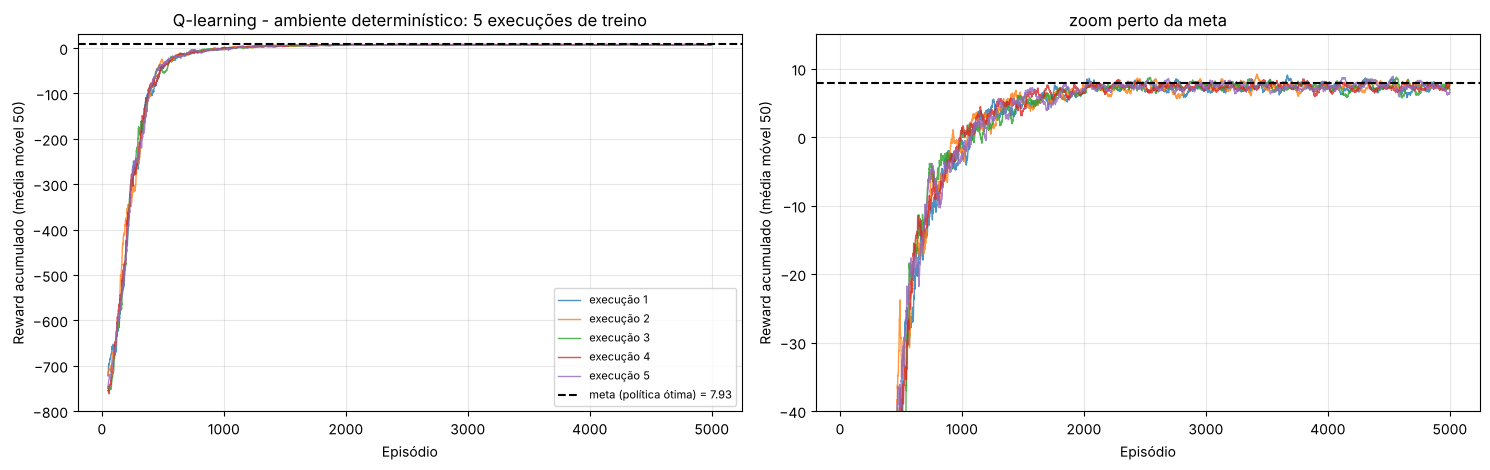

In [3]:
display(figura_com_zoom(plot_execucoes, treino, metas, 'deterministico', 'Q-learning')); plt.close('all')

## Atividade 2: teste da q-table do Q-learning (100 execuções)

A tabela mostra a q-table da **execução 1** (a pedida pelo enunciado) e também a média das 5 q-tables treinadas, para mostrar que o resultado não depende da semente.

In [4]:
def tabela_teste(chaves, rotulos=None):
    linhas = []
    for (amb_tr, alg, amb_te) in chaves:
        d = testes[(amb_tr, alg, amb_te)]
        p, r, s = d['passos'], d['rewards'], d['sucesso']
        linhas.append({
            'algoritmo': alg, 'treinado em': amb_tr, 'testado em': amb_te,
            'timesteps média (exec. 1)': p[0].mean(), 'timesteps desvio (exec. 1)': p[0].std(),
            'sucesso (exec. 1)': f'{s[0].mean():.0%}',
            'timesteps média (5 exec.)': p.mean(), 'timesteps desvio (5 exec.)': p.std(),
            'sucesso (5 exec.)': f'{s.mean():.1%}', 'reward médio (5 exec.)': r.mean(),
        })
    return pd.DataFrame(linhas)

tabela_teste([('deterministico', 'Q-learning', 'deterministico')])

,algoritmo,treinado em,testado em,timesteps média (exec. 1),timesteps desvio (exec. 1),sucesso (exec. 1),timesteps média (5 exec.),timesteps desvio (5 exec.),sucesso (5 exec.),reward médio (5 exec.)
0,Q-learning,deterministico,deterministico,12.95,2.51,100%,12.96,2.52,100.0%,8.04


O agente Q-learning resolve 100% dos episódios com **≈ 13 timesteps** em média. Como no Taxi o reward de um episódio bem sucedido é `21 − passos`, a meta de 7,93 equivale a ≈ 13,07 passos esperados: **o Q-learning chegou à política ótima** (a pequena diferença vem da amostra de 100 estados iniciais). O desvio de ≈ 2,5 passos não é erro do agente; ele vem das diferentes posições iniciais de táxi, passageiro e destino.

## Atividade 1 e 2 para o Sarsa

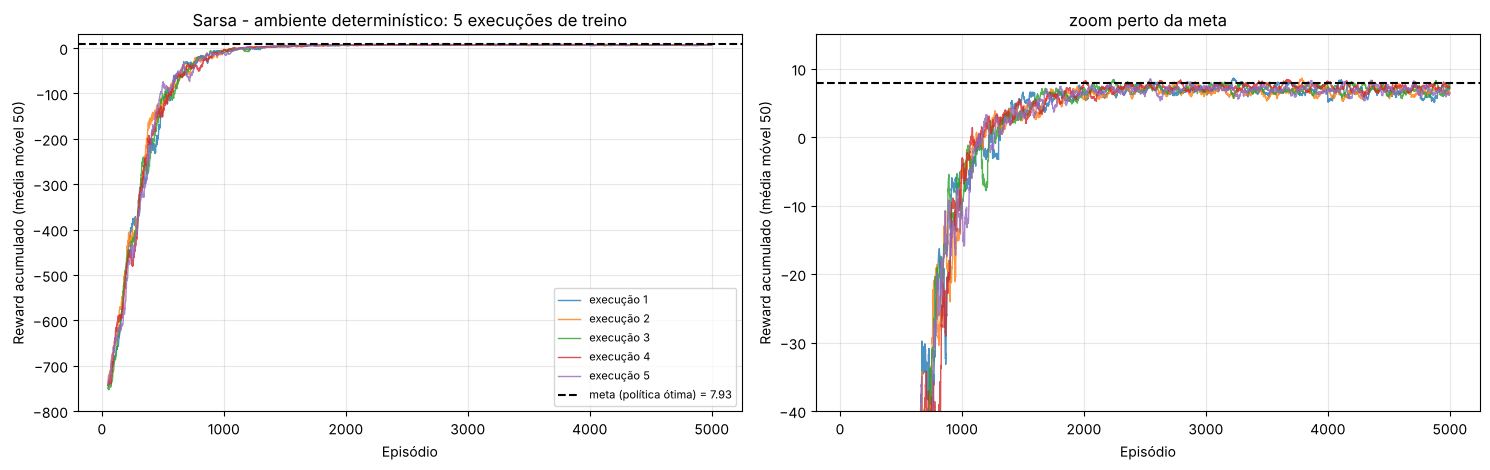

,algoritmo,treinado em,testado em,timesteps média (exec. 1),timesteps desvio (exec. 1),sucesso (exec. 1),timesteps média (5 exec.),timesteps desvio (5 exec.),sucesso (5 exec.),reward médio (5 exec.)
0,Q-learning,deterministico,deterministico,12.95,2.51,100%,12.96,2.52,100.0%,8.04
1,Sarsa,deterministico,deterministico,13.29,2.73,100%,13.44,2.80,100.0%,7.56


In [5]:
display(figura_com_zoom(plot_execucoes, treino, metas, 'deterministico', 'Sarsa')); plt.close('all')
tabela_teste([('deterministico', 'Q-learning', 'deterministico'), ('deterministico', 'Sarsa', 'deterministico')])

## Atividade 3: comparação Q-learning × Sarsa (determinístico)

Gráfico único com a média das 5 execuções de cada algoritmo; a faixa sombreada é ±1 desvio padrão entre as execuções.

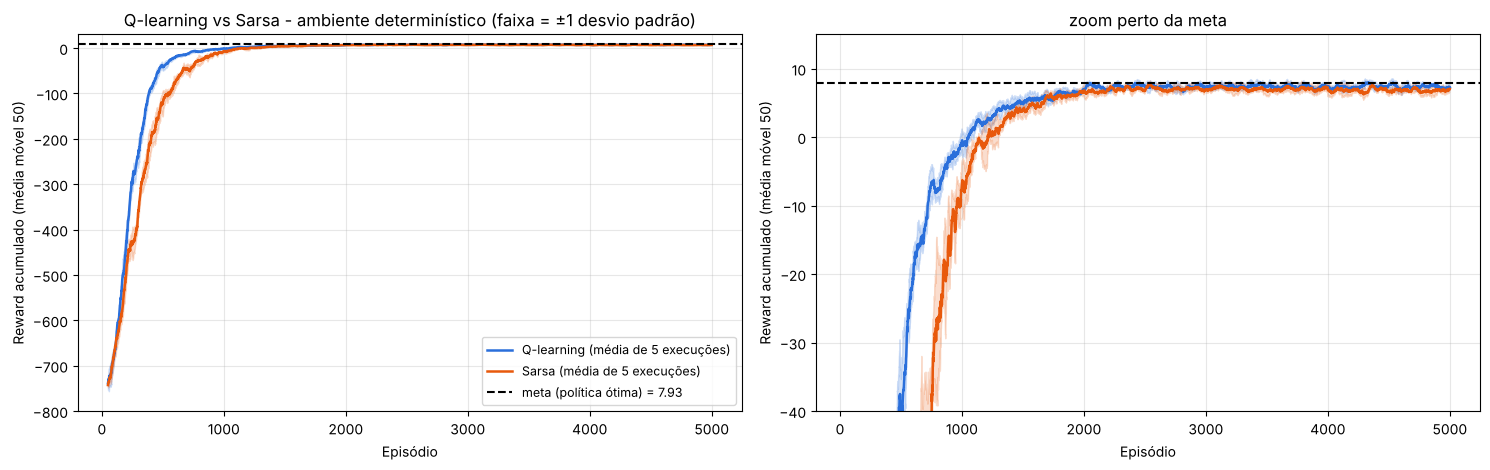

In [6]:
display(figura_com_zoom(plot_comparacao, treino, metas, 'deterministico')); plt.close('all')

In [7]:
def tabela_treino(amb):
    linhas = []
    for alg in ALGORITMOS:
        r = treino[(amb, alg)]['rewards']
        conv10 = [episodio_convergencia(x, metas[amb], tolerancia=10) for x in r]
        conv3 = [episodio_convergencia(x, metas[amb], tolerancia=3) for x in r]
        linhas.append({
            'algoritmo': alg,
            'episódio em que chega a meta−10 (média)': np.mean(conv10),
            'episódio em que chega a meta−3 (média)': np.mean(conv3),
            'reward médio nos 500 primeiros episódios': r[:, :500].mean(),
            'reward médio nos 500 últimos episódios': r[:, -500:].mean(),
            'reward total no treino (área sob a curva)': r.sum(1).mean(),
        })
    return pd.DataFrame(linhas).set_index('algoritmo')

tabela_treino('deterministico')

,episódio em que chega a meta−10 (média),episódio em que chega a meta−3 (média),reward médio nos 500 primeiros episódios,reward médio nos 500 últimos episódios,reward total no treino (área sob a curva)
algoritmo,,,,,
Q-learning,929.6,1305.0,-327.24,7.34,-142044.6
Sarsa,1078.2,1503.8,-405.61,6.86,-198829.0


### Discussão: Q-learning × Sarsa no ambiente determinístico

**Eficiência no aprendizado.** O Q-learning aprende mais rápido: a curva azul sobe antes e chega perto da meta (meta − 10) por volta do episódio 930, contra ≈ 1080 do Sarsa, acumulando bem menos reward negativo durante o treino. O motivo está no alvo da atualização:

* **Q-learning (off-policy)** usa `max_a Q(s', a)`: aprende o valor da política gulosa mesmo enquanto age de forma exploratória. As ações aleatórias do início não "contaminam" a estimativa.
* **Sarsa (on-policy)** usa `Q(s', a')`, com `a'` sorteada pela própria política ε-greedy. Enquanto ε é alto, o valor estimado inclui o custo das ações aleatórias futuras (bater em paredes, pickups/dropoffs ilegais que custam −10), então os valores convergem mais devagar.

**Reward final do treino.** Nos últimos 500 episódios o Sarsa fica um pouco abaixo do Q-learning e mais longe da meta. Ainda há 1% de exploração nessa fase e o Sarsa aprende o valor *dessa* política exploratória, sendo mais conservador; além disso, algumas execuções ainda não tinham estimado bem os estados raros.

**Desempenho final.** Na política gulosa os dois resolvem 100% dos episódios. O Q-learning é ótimo (≈ 13,0 passos). O Sarsa fica muito perto (≈ 13,3 a 13,4), com uma pequena sub-otimalidade em alguns estados pouco visitados, onde a política escolhida faz um caminho um ou dois passos mais longo.

Neste ambiente não há "penhascos" (como no Cliff Walking), então a vantagem típica do Sarsa, de aprender caminhos mais seguros sob exploração, não aparece: o Q-learning é melhor nas duas dimensões.

---
# Parte B: ambiente não determinístico (`is_rainy=True, rainy_probability=0.6`)

Com chuva, cada movimento só sai como pretendido em 60% das vezes; nos outros 40% o táxi desliza para uma das laterais. Pickup e dropoff não são afetados. Se o movimento pretendido bate numa parede, o táxi fica parado (sem deslizar).

## Atividade 4: a q-table do ambiente determinístico funciona com chuva?

In [8]:
tabela_teste([('deterministico', 'Q-learning', 'deterministico'), ('deterministico', 'Q-learning', 'chuvoso'),
              ('deterministico', 'Sarsa', 'deterministico'), ('deterministico', 'Sarsa', 'chuvoso')])

,algoritmo,treinado em,testado em,timesteps média (exec. 1),timesteps desvio (exec. 1),sucesso (exec. 1),timesteps média (5 exec.),timesteps desvio (5 exec.),sucesso (5 exec.),reward médio (5 exec.)
0,Q-learning,deterministico,deterministico,12.95,2.51,100%,12.96,2.52,100.0%,8.04
1,Q-learning,deterministico,chuvoso,24.76,9.57,100%,28.72,62.23,99.6%,-7.81
2,Sarsa,deterministico,deterministico,13.29,2.73,100%,13.44,2.80,100.0%,7.56
3,Sarsa,deterministico,chuvoso,25.61,10.57,100%,41.10,122.63,98.4%,-20.43


Para a q-table pedida (execução 1), a política aprendida sem chuva **ainda completa 100% dos episódios** no ambiente chuvoso, mas precisa de **≈ 25 timesteps em vez de 13** (quase o dobro), e o desvio padrão sobe de ≈ 2,5 para ≈ 10.

Por que funciona: a política é uma tabela com uma ação para *cada* estado. Quando a chuva joga o táxi para uma casa que não estava no plano, o agente apenas aplica a ação daquele novo estado, que continua apontando para o objetivo. Como 60% dos movimentos dão certo, o táxi acaba chegando, com "desvios e correções" pelo caminho. Daí o aumento da média (passos extras para corrigir) e da variância (o número de desvios é aleatório).

Mas olhando as 5 q-tables o resultado **não é robusto**: algumas execuções falham em uma parte dos episódios (veja a coluna de sucesso nas 5 execuções). O diagnóstico abaixo mostra por quê.

In [9]:
from comum import carregar_q_tables, make_env, SEMENTE_TESTE
from collections import Counter

NOMES_ACAO = ['sul', 'norte', 'leste', 'oeste', 'pickup', 'dropoff']
LOCAIS = ['R', 'G', 'Y', 'B', 'no táxi']

def diagnostico(amb_tr, alg, amb_te, run):
    qt = carregar_q_tables(amb_tr, alg)[run]
    env = make_env(amb_te, MAX_PASSOS_TESTE)
    for k in range(N_TESTES):
        s, _ = env.reset(seed=SEMENTE_TESTE + k)
        traj, done, term = [], False, False
        while not done:
            a = int(np.argmax(qt[s])); traj.append((s, a))
            s, _, term, trunc, _ = env.step(a); done = term or trunc
        if not term:
            print(f'{alg} treinado em {amb_tr}, execução {run + 1}, testado em {amb_te}: episódio {k} falhou.')
            for (st, a), n in Counter(traj).most_common(3):
                lin, col, pas, dst = env.unwrapped.decode(st)
                print(f'   táxi em (linha {lin}, coluna {col}), passageiro {LOCAIS[pas]}, destino {LOCAIS[dst]}: '
                      f'ação "{NOMES_ACAO[a]}" repetida {n} vezes')
            return

diagnostico('deterministico', 'Q-learning', 'chuvoso', 4)
diagnostico('deterministico', 'Sarsa', 'chuvoso', 2)

Q-learning treinado em deterministico, execução 5, testado em chuvoso: episódio 56 falhou.
   táxi em (linha 4, coluna 1), passageiro no táxi, destino G: ação "oeste" repetida 969 vezes
   táxi em (linha 2, coluna 1), passageiro Y, destino G: ação "oeste" repetida 4 vezes
   táxi em (linha 3, coluna 1), passageiro Y, destino G: ação "norte" repetida 4 vezes
Sarsa treinado em deterministico, execução 3, testado em chuvoso: episódio 34 falhou.
   táxi em (linha 4, coluna 1), passageiro no táxi, destino R: ação "sul" repetida 984 vezes
   táxi em (linha 1, coluna 4), passageiro no táxi, destino R: ação "oeste" repetida 2 vezes
   táxi em (linha 2, coluna 2), passageiro no táxi, destino R: ação "oeste" repetida 2 vezes


Nas falhas o táxi fica **preso contra uma parede ou a borda do mapa**: está em um estado em que a política escolhe um movimento bloqueado. No Taxi-v4 chuvoso, um movimento bloqueado não gera deslize, então o táxi fica parado para sempre repetindo a mesma ação.

Esses estados (por exemplo, com o passageiro já no táxi numa posição fora da rota ótima) quase nunca são visitados quando o ambiente é determinístico e o agente segue a rota ótima, então a q-table deles ficou mal estimada. **No ambiente chuvoso esses estados passam a ser visitados com frequência**, porque a chuva tira o táxi da rota. É exatamente o problema de generalização de uma política aprendida em um ambiente para outro com dinâmica diferente.

## Atividade 5: treinando com chuva

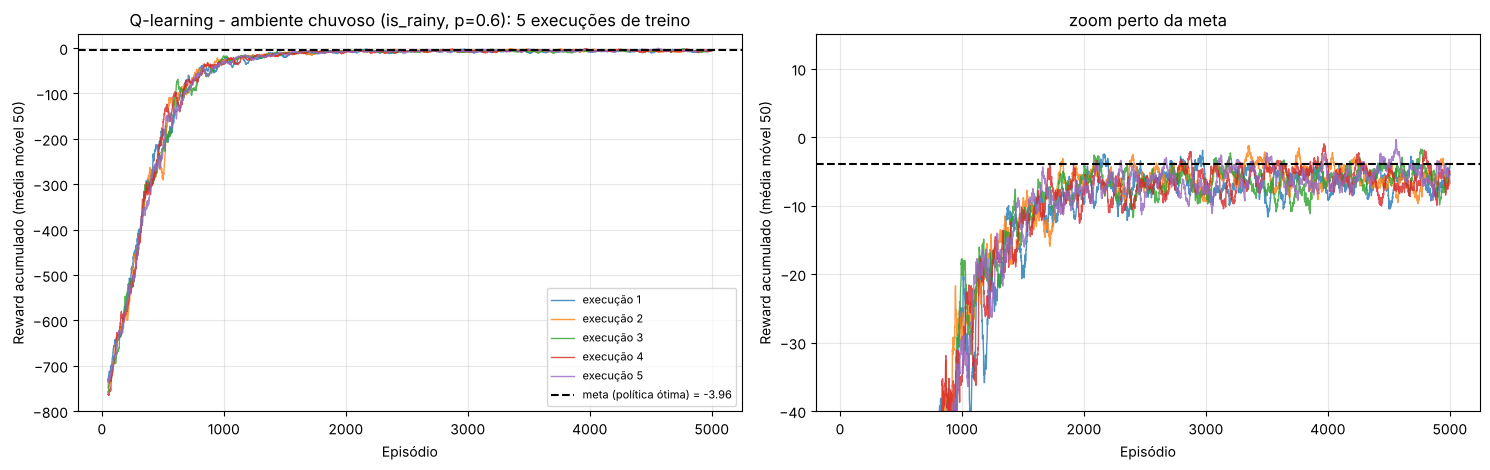

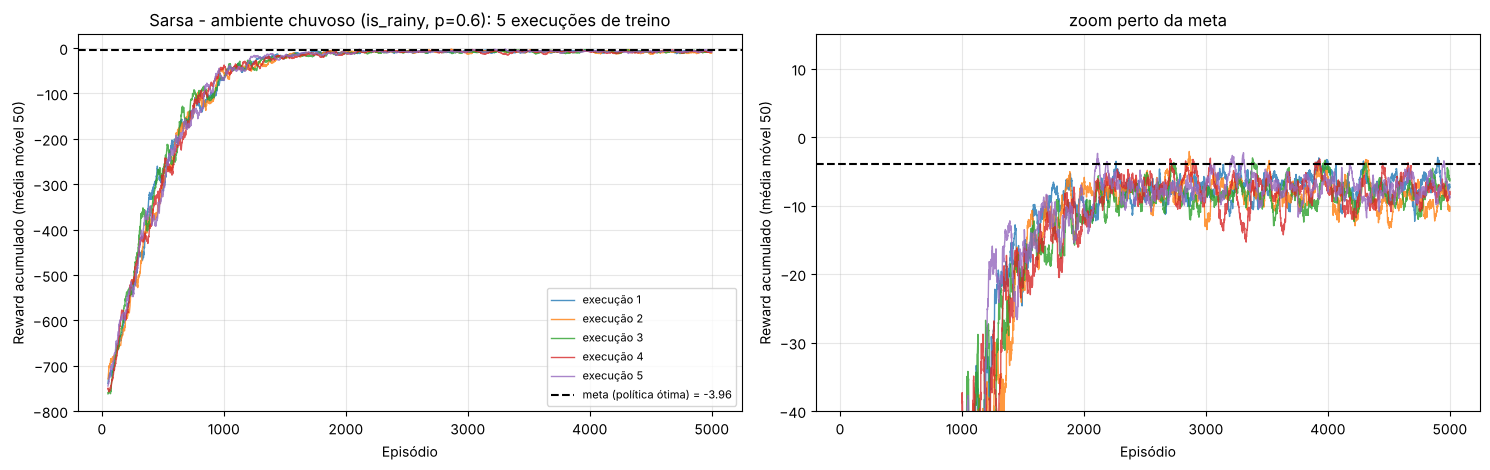

In [10]:
display(figura_com_zoom(plot_execucoes, treino, metas, 'chuvoso', 'Q-learning')); plt.close('all')
display(figura_com_zoom(plot_execucoes, treino, metas, 'chuvoso', 'Sarsa')); plt.close('all')

Comparação Q-learning × Sarsa no ambiente chuvoso, no mesmo gráfico:

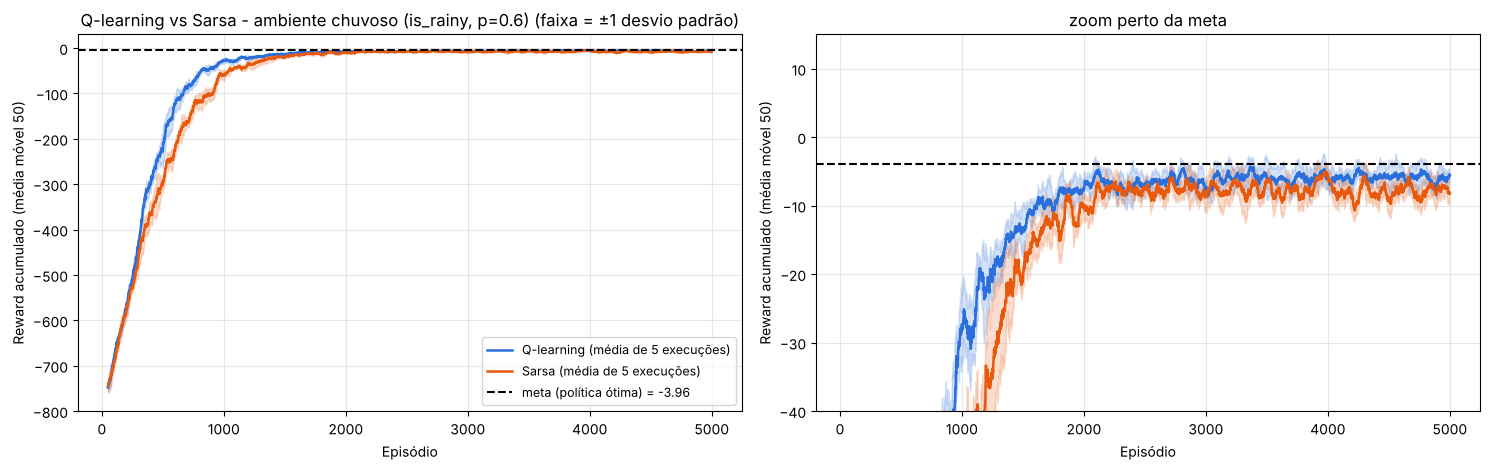

episódio em que chega a meta−10 (média)  \
               algoritmo                                             
determinístico Q-learning                                    929.6   
               Sarsa                                        1078.2   
chuvoso        Q-learning                                   1354.0   
               Sarsa                                        1505.8   

                           episódio em que chega a meta−3 (média)  \
               algoritmo                                            
determinístico Q-learning                                  1305.0   
               Sarsa                                       1503.8   
chuvoso        Q-learning                                  1725.4   
               Sarsa                                       1978.2   

                           reward médio nos 500 primeiros episódios  \
               algoritmo                                              
determinístico Q-learning                                   -327.24   
               Sarsa                                        -405.61   
chuvoso        Q-learning                                   -466.29   
               Sarsa                                        -502.26   

                           reward médio nos 500 últimos episódios  \
               algoritmo                                            
determinístico Q-learning                                    7.34   
               Sarsa                                         6.86   
chuvoso        Q-learning                                   -5.91   
               Sarsa                                        -7.73   

                           reward total no treino (área sob a curva)  
               algoritmo                                              
determinístico Q-learning                                  -142044.6  
               Sarsa                                       -198829.0  
chuvoso        Q-learning                                  -303781.0  
               Sarsa                                       -366427.0

In [11]:
display(figura_com_zoom(plot_comparacao, treino, metas, 'chuvoso')); plt.close('all')
pd.concat({'determinístico': tabela_treino('deterministico'), 'chuvoso': tabela_treino('chuvoso')})

In [12]:
tabela_teste([('deterministico', 'Q-learning', 'chuvoso'), ('chuvoso', 'Q-learning', 'chuvoso'),
              ('deterministico', 'Sarsa', 'chuvoso'), ('chuvoso', 'Sarsa', 'chuvoso')])

,algoritmo,treinado em,testado em,timesteps média (exec. 1),timesteps desvio (exec. 1),sucesso (exec. 1),timesteps média (5 exec.),timesteps desvio (5 exec.),sucesso (5 exec.),reward médio (5 exec.)
0,Q-learning,deterministico,chuvoso,24.76,9.57,100%,28.72,62.23,99.6%,-7.81
1,Q-learning,chuvoso,chuvoso,24.53,8.60,100%,24.62,8.80,100.0%,-3.62
2,Sarsa,deterministico,chuvoso,25.61,10.57,100%,41.10,122.63,98.4%,-20.43
3,Sarsa,chuvoso,chuvoso,26.51,11.06,100%,26.36,10.33,100.0%,-5.36


### Discussão: treinar no ambiente chuvoso

**Aprendizado mais lento e mais ruidoso.** Com chuva os dois algoritmos levam mais episódios para chegar perto da meta (≈ 1350 a 1500 episódios para meta − 10, contra ≈ 930 a 1080 no determinístico) e as curvas oscilam mais mesmo depois de convergir. A mesma ação no mesmo estado agora gera resultados diferentes, então o erro TD é ruidoso e a q-table precisa de muito mais amostras para estimar valores *esperados*.

**A meta é mais baixa.** Mesmo a política ótima só consegue ≈ −3,96 de reward esperado (contra 7,93), porque cada movimento falha 40% das vezes. Os agentes chegam perto dessa meta (Q-learning ≈ −6 de média nos últimos 500 episódios de treino, ainda com 1% de exploração).

**Q-learning × Sarsa com chuva.** A diferença aumenta: o Q-learning aprende mais rápido e termina mais perto da meta. O Sarsa, por ser on-policy, soma ao ruído da chuva o ruído da própria exploração no alvo `Q(s', a')`, o que deixa as estimativas mais variáveis. No teste, o Q-learning chuvoso faz ≈ 24,6 passos e o Sarsa ≈ 26,4, os dois com 100% de sucesso nas 5 execuções.

**Treinar com chuva melhora o desempenho com chuva.** Em relação à atividade 4, as políticas treinadas com chuva:

* têm **100% de sucesso em todas as 5 execuções** (as treinadas sem chuva falhavam em parte dos episódios em algumas execuções);
* têm média de passos menor e, principalmente, **desvio padrão muito menor** (≈ 9 a 10 contra dezenas, quando consideramos as 5 execuções).

Os estados "fora da rota" foram visitados no treino e aprenderam boas ações, e os valores refletem o risco dos deslizes.
A média de ≈ 25 passos com chuva, contra 13 sem chuva, é o custo inevitável da aleatoriedade, não uma deficiência do agente: ela corresponde à meta ótima de ≈ −4.

### Análise extra: a política aprendida com chuva funciona sem chuva?

In [13]:
tabela_teste([('chuvoso', 'Q-learning', 'deterministico'), ('chuvoso', 'Sarsa', 'deterministico')])

,algoritmo,treinado em,testado em,timesteps média (exec. 1),timesteps desvio (exec. 1),sucesso (exec. 1),timesteps média (5 exec.),timesteps desvio (5 exec.),sucesso (5 exec.),reward médio (5 exec.)
0,Q-learning,chuvoso,deterministico,13.37,2.58,100%,13.25,2.61,100.0%,7.75
1,Sarsa,chuvoso,deterministico,23.58,98.18,99%,86.53,258.24,92.6%,-67.08


In [14]:
diagnostico('chuvoso', 'Sarsa', 'deterministico', 1)

Sarsa treinado em chuvoso, execução 2, testado em deterministico: episódio 8 falhou.
   táxi em (linha 1, coluna 4), passageiro G, destino Y: ação "oeste" repetida 500 vezes
   táxi em (linha 1, coluna 3), passageiro G, destino Y: ação "leste" repetida 499 vezes
   táxi em (linha 2, coluna 4), passageiro G, destino Y: ação "norte" repetida 1 vezes


O Q-learning treinado com chuva continua praticamente ótimo sem chuva (≈ 13,3 passos, 100% de sucesso). Já o Sarsa treinado com chuva **falha em ≈ 7% dos episódios** no ambiente determinístico: a política tem *ciclos*, como andar para oeste em uma casa e para leste na seguinte. Com chuva, o deslize aleatório acaba quebrando o ciclo, então isso quase não custava nada durante o treino e o Sarsa (que estima o valor da política que realmente executa, com ruído) não precisou corrigir. Sem chuva, o ciclo se repete para sempre.

Ou seja, a política aprendida "conta" com a aleatoriedade do ambiente em que foi treinada.

---
# Conclusões

| | Q-learning | Sarsa |
|---|---|---|
| Velocidade de aprendizado (det.) | mais rápido | mais lento |
| Teste no determinístico | ótimo, ≈ 13,0 passos | ≈ 13,3 a 13,4 passos |
| Velocidade de aprendizado (chuva) | mais rápido | mais lento e mais ruidoso |
| Teste com chuva (treinado com chuva) | ≈ 24,6 passos, 100% | ≈ 26,4 passos, 100% |

1. **Q-learning foi superior no Taxi-v4 nos dois ambientes**, tanto em eficiência de aprendizado quanto em desempenho final. Como o alvo é `max Q`, ele aprende a política gulosa diretamente e não é penalizado pela exploração. Não há penhascos no Taxi, então a cautela do Sarsa não traz benefício.
2. **O não determinismo deixa o aprendizado mais lento e mais ruidoso** e reduz o melhor desempenho possível (meta de 7,93 para −3,96; de ≈ 13 para ≈ 25 passos), mesmo para uma política ótima.
3. **Uma política treinada sem chuva funciona razoavelmente com chuva** porque a q-table cobre todos os estados, mas fica **frágil**: estados fora da rota ótima foram pouco treinados e, em algumas execuções, o táxi fica preso contra uma parede.
4. **Treinar no ambiente que será usado é a forma de obter uma política robusta**: com chuva no treino, as falhas desaparecem e o desvio padrão dos passos cai.
5. A política também se adapta ao ruído do ambiente de treino: o Sarsa treinado com chuva tem ciclos que só se resolvem por causa dos deslizes, e falha quando a chuva é retirada.